In [79]:

# Importe NumPy pour les tableaux.
import numpy as np
# Importe les outils d affichage.
import matplotlib.pyplot as plt
# Importe la lecture des images.
from PIL import Image
# Importe les fonctions CUDA.
from numba import cuda
# Importe la mesure du temps.
import time

# Affiche une information.
print("CUDA disponible :", cuda.is_available())

CUDA disponible : True


In [80]:

# Compile la fonction comme kernel GPU.
@cuda.jit  #pour transforme la fonction en kernel destiné au GPU 
# Definit une fonction ou un kernel.
def coordinates2D():   #pour  Créer le kernel coordinates2D()  
    # Lit la coordonnee x locale.
    tx = cuda.threadIdx.x   #  la  position horizontale du thread dans son bloc. 
    # Lit la coordonnee y locale.
    ty = cuda.threadIdx.y   # verticale 
 
    # Affiche une information.
    print(tx, ty)  # Affichage du deux position 

In [81]:

# Lance le kernel CUDA.
coordinates2D[(1, 1), (4, 4)]()  #Exécuter avec un bloc de [ 4 × 4 ]threads
# Attend la fin du GPU.
cuda.synchronize()  

c:\Users\GiGi\Desktop\TPAML\.venv\Lib\site-packages\numba_cuda\numba\cuda\dispatcher.py:748: NumbaPerformanceWarning: Grid size 1 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


In [82]:

# Compile la fonction comme kernel GPU.
@cuda.jit
# Definit une fonction ou un kernel.
def coordinatesGlobal2D():

    # Position locale
    # Lit la coordonnee x locale.
    tx = cuda.threadIdx.x
    # Lit la coordonnee y locale.
    ty = cuda.threadIdx.y

    # Position globale automatique ////  # calcule automatiquement 
    # les coordonnées globales
    # Calcule la position globale du thread.
    x, y = cuda.grid(2)

    # Position globale manuelle
    # Calcule x manuellement.
    x_manual = (
        # Execute cette instruction.
        cuda.blockIdx.x * cuda.blockDim.x
        # Execute cette instruction.
        + cuda.threadIdx.x
    # Execute cette instruction.
    )

    # Calcule y manuellement.
    y_manual = (
        # Execute cette instruction.
        cuda.blockIdx.y * cuda.blockDim.y
        # Execute cette instruction.
        + cuda.threadIdx.y
    # Execute cette instruction.
    )

    # Affiche une information.
    print(tx, ty, x, y, x_manual, y_manual)

In [83]:

# Lance le kernel CUDA.
coordinatesGlobal2D[(1, 1), (4, 4)]()
# Attend la fin du GPU.
cuda.synchronize()

c:\Users\GiGi\Desktop\TPAML\.venv\Lib\site-packages\numba_cuda\numba\cuda\dispatcher.py:748: NumbaPerformanceWarning: Grid size 1 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


In [84]:

# Créer une matrice de 16 × 16
# Defin it une dimension.
H = 16
# Defin it une dimension.
W = 16

# Cree une matrice de zeros.
matrix = np.zeros((H, W), dtype=np.int32) #une matrice remplie par des 0 

# Copie la matrice vers le GPU.
d_matrix = cuda.to_device(matrix) #copie la matrice de la RAM vers la mémoire du GPU  

In [85]:

# Compile la fonction comme kernel GPU.
@cuda.jit
# Definit une fonction ou un kernel.
def fillMatrix(matrix):

    # Calcule la position globale du thread.
    x, y = cuda.grid(2)

    # Recupere les dimensions du tableau.
    H, W = matrix.shape

    # Verifie les limites.
    if x < W and y < H:
        # Ecrit la valeur du pixel.
        matrix[y, x] = y * W + x

In [86]:

# Definit la taille du bloc.
threads_per_block = (8, 8)  # la taille du block 

# Calcule le nombre de blocs.
blocks_x = (W + 7) // 8
# Calcule le nombre de blocs.
blocks_y = (H + 7) // 8

# Definit la taille de la grille.
grid_dim = (blocks_x, blocks_y)  # nbr du bloc

# Lance le kernel CUDA.
fillMatrix[grid_dim, threads_per_block](d_matrix)

# Attend la fin du GPU.
cuda.synchronize()

# Recupere le resultat sur le CPU.
result = d_matrix.copy_to_host()

# Affiche une information.
print(result)

c:\Users\GiGi\Desktop\TPAML\.venv\Lib\site-packages\numba_cuda\numba\cuda\dispatcher.py:748: NumbaPerformanceWarning: Grid size 4 will likely result in GPU under-utilization due to low occupancy.
  warn(errors.NumbaPerformanceWarning(msg))


[[  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15]
 [ 16  17  18  19  20  21  22  23  24  25  26  27  28  29  30  31]
 [ 32  33  34  35  36  37  38  39  40  41  42  43  44  45  46  47]
 [ 48  49  50  51  52  53  54  55  56  57  58  59  60  61  62  63]
 [ 64  65  66  67  68  69  70  71  72  73  74  75  76  77  78  79]
 [ 80  81  82  83  84  85  86  87  88  89  90  91  92  93  94  95]
 [ 96  97  98  99 100 101 102 103 104 105 106 107 108 109 110 111]
 [112 113 114 115 116 117 118 119 120 121 122 123 124 125 126 127]
 [128 129 130 131 132 133 134 135 136 137 138 139 140 141 142 143]
 [144 145 146 147 148 149 150 151 152 153 154 155 156 157 158 159]
 [160 161 162 163 164 165 166 167 168 169 170 171 172 173 174 175]
 [176 177 178 179 180 181 182 183 184 185 186 187 188 189 190 191]
 [192 193 194 195 196 197 198 199 200 201 202 203 204 205 206 207]
 [208 209 210 211 212 213 214 215 216 217 218 219 220 221 222 223]
 [224 225 226 227 228 229 230 231 232 233 234 235 236 237 238 

In [87]:

#Tester les limites de la matrice
# Defin it une dimension.
H = 750
# Defin it une dimension.
W = 1300

# Cree une matrice de zeros.
matrix = np.zeros((H, W), dtype=np.int32)
# Copie la matrice vers le GPU.
d_matrix = cuda.to_device(matrix)

# Definit la taille du bloc.
threads_per_block = (16, 16)

# Calcule le nombre de blocs.
blocks_x = (W + 15) // 16
# Calcule le nombre de blocs.
blocks_y = (H + 15) // 16

# Definit la taille de la grille.
grid_dim = (blocks_x, blocks_y)

# Affiche une information.
print(grid_dim)

(82, 47)


In [88]:

#le professeur demande d'essayer sans protection
# Compile la fonction comme kernel GPU.
@cuda.jit
# Definit une fonction ou un kernel.
def fillMatrixSansGuard(matrix):
    # Calcule la position globale du thread.
    x, y = cuda.grid(2)
    # Recupere les dimensions du tableau.
    H, W = matrix.shape
    # Ecrit la valeur du pixel.
    matrix[y, x] = y * W + x

In [89]:

#np.testing.assert_array_equal() 
# vérifie que les valeurs calculées sont identiques aux valeurs attendues.
# Copie la matrice vers le GPU.
d_matrix = cuda.to_device(matrix)

# Lance le kernel CUDA.
fillMatrix[grid_dim, threads_per_block](d_matrix)
# Attend la fin du GPU.
cuda.synchronize()

# Recupere le resultat sur le CPU.
result = d_matrix.copy_to_host()

# Construit le resultat attendu.
expected = np.arange(
    # Execute cette instruction.
    H * W, dtype=np.int32
# Execute cette instruction.
).reshape(H, W)

# Verifie le resultat.
np.testing.assert_array_equal(result, expected)

# Affiche une information.
print("Matrice correcte !")

Matrice correcte !


In [90]:

# Compile une fonction utilisable sur le GPU.
@cuda.jit(device=True)
#device=True signifie que cette fonction 
# est appelée depuis du code exécuté sur le GPU.
# Definit une fonction ou un kernel.
def rgbToGray(r, g, b):
    # Renvoie le resultat.
    return 0.299*r + 0.587*g + 0.114*b # Créer la fonction rgbToGray()
#Le but est de convertir un pixel RGB en niveau de gris 


In [91]:

#Ce kernel :
#1. Trouve la position du pixel.
#2. Vérifie qu'elle est dans l'image.
#3. Lit ses composantes rouge, verte et bleue.
#4. Calcule sa valeur grise.
#5. Enregistre le résultat.
# Compile la fonction comme kernel GPU.
@cuda.jit
# Definit une fonction ou un kernel.
def grayscaleKernel(d_input, d_output):

    # Calcule la position globale du thread.
    x, y = cuda.grid(2)

    # Recupere les dimensions du tableau.
    H, W = d_output.shape

    # Verifie les limites.
    if x < W and y < H:

        # Lit le canal rouge.
        r = d_input[y, x, 0]
        # Lit le canal vert.
        g = d_input[y, x, 1]
        # Lit le canal bleu.
        b = d_input[y, x, 2]

        # Ecrit le pixel converti.
        d_output[y, x] = rgbToGray(r, g, b)

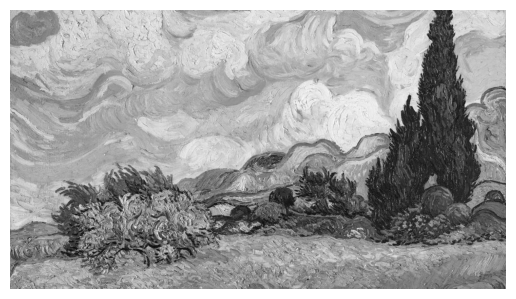

In [92]:

# Charge l image comme tableau.
image = np.array(
    # Execute cette instruction.
    Image.open("van_gogh.jpg").convert("RGB")
# Execute cette instruction.
)

# Recupere les dimensions du tableau.
H, W, C = image.shape

# Copie l image vers le GPU.
d_input = cuda.to_device(image)
# Reserve la sortie sur le GPU.
d_output = cuda.device_array((H, W), dtype=np.uint8)

# Choisit la forme du bloc.
block_dim = (16, 16)

# Definit la taille de la grille.
grid_dim = (
    # Execute cette instruction.
    (W + 15) // 16,
    # Execute cette instruction.
    (H + 15) // 16
# Execute cette instruction.
)

# Lance le kernel CUDA.
grayscaleKernel[grid_dim, block_dim](d_input, d_output)

# Attend la fin du GPU.
cuda.synchronize()

# Calcule le niveau de gris.
gray = d_output.copy_to_host()

# Affiche l image.
plt.imshow(gray, cmap="gray")
# Affiche l image.
plt.axis("off")
# Affiche l image.
plt.show()

In [12]:
image_benchmark = np.random.default_rng(42).integers(
    0, 256, size=(2160, 3840, 3), dtype=np.uint8
)
H, W, _ = image_benchmark.shape
d_input = cuda.to_device(image_benchmark)
d_output = cuda.device_array((H, W), dtype=np.uint8)

def mesurer_kernel(block_dim, repetitions=5):
    bx, by = block_dim
    grid_dim = ((W + bx - 1) // bx, (H + by - 1) // by)
    grayscaleKernel[grid_dim, block_dim](d_input, d_output)
    cuda.synchronize()
    temps = []
    for _ in range(repetitions):
        debut = time.perf_counter()
        grayscaleKernel[grid_dim, block_dim](d_input, d_output)
        cuda.synchronize()
        temps.append((time.perf_counter() - debut) * 1000)
    return float(np.median(temps))

configurations = [(16, 16), (32, 8), (8, 32), (256, 1), (1, 256)]
resultats_benchmark = {}
for configuration in configurations:
    resultats_benchmark[configuration] = mesurer_kernel(configuration)
    print(configuration, ":", resultats_benchmark[configuration], "ms")

meilleure_configuration = min(resultats_benchmark, key=resultats_benchmark.get)
print("Configuration la plus rapide :", meilleure_configuration)

(16, 16) : 0.36890001501888037 ms
(32, 8) : 0.4031999269500375 ms
(8, 32) : 0.3736999351531267 ms
(256, 1) : 0.36669999826699495 ms
(1, 256) : 0.7929999846965075 ms
Configuration la plus rapide : (256, 1)


# Partie 5 — Granularité des threads

In [13]:
@cuda.jit
def grayscaleKernel2x(d_input, d_output):
    tx, y = cuda.grid(2)
    x = tx * 2
    H, W = d_output.shape
    if y < H:
        for offset in range(2):
            pixel_x = x + offset
            if pixel_x < W:
                d_output[y, pixel_x] = rgbToGray(
                    d_input[y, pixel_x, 0], d_input[y, pixel_x, 1], d_input[y, pixel_x, 2]
                )

@cuda.jit
def grayscaleGridStride(d_input, d_output):
    x0, y0 = cuda.grid(2)
    H, W = d_output.shape
    stride_x = cuda.gridDim.x * cuda.blockDim.x
    stride_y = cuda.gridDim.y * cuda.blockDim.y
    for y in range(y0, H, stride_y):
        for x in range(x0, W, stride_x):
            d_output[y, x] = rgbToGray(
                d_input[y, x, 0], d_input[y, x, 1], d_input[y, x, 2]
            )

In [14]:
block_dim = (16, 16)
grid_pixel = ((W + 15) // 16, (H + 15) // 16)
grid_2x = ((W + 31) // 32, (H + 15) // 16)
grid_stride = (16, 8)

sorties = []
for kernel, grid in [
    (grayscaleKernel, grid_pixel),
    (grayscaleKernel2x, grid_2x),
    (grayscaleGridStride, grid_stride),
]:
    d_test = cuda.device_array((H, W), dtype=np.uint8)
    kernel[grid, block_dim](d_input, d_test)
    cuda.synchronize()
    sortie = d_test.copy_to_host()
    sorties.append(sortie)
    debut = time.perf_counter()
    kernel[grid, block_dim](d_input, d_test)
    cuda.synchronize()
    print(kernel.py_func.__name__, ":", (time.perf_counter() - debut) * 1000, "ms")

np.testing.assert_array_equal(sorties[0], sorties[1])
np.testing.assert_array_equal(sorties[0], sorties[2])
print("Les trois kernels produisent le même résultat.")

grayscaleKernel : 0.5799001082777977 ms
grayscaleKernel2x : 0.7877000607550144 ms


grayscaleGridStride : 0.9119999594986439 ms
Les trois kernels produisent le même résultat.


In [15]:
debut = time.perf_counter()
gray_cpu = (
    0.299 * image_benchmark[:, :, 0]
    + 0.587 * image_benchmark[:, :, 1]
    + 0.114 * image_benchmark[:, :, 2]
).astype(np.uint8)
temps_cpu = (time.perf_counter() - debut) * 1000

debut = time.perf_counter()
d_input_total = cuda.to_device(image_benchmark)
d_output_total = cuda.device_array((H, W), dtype=np.uint8)
grayscaleKernel[grid_pixel, block_dim](d_input_total, d_output_total)
cuda.synchronize()
gray_gpu = d_output_total.copy_to_host()
temps_gpu_total = (time.perf_counter() - debut) * 1000

np.testing.assert_allclose(gray_cpu, gray_gpu, atol=1)
print("Écart maximal CPU/GPU :", np.max(np.abs(gray_cpu.astype(np.int16) - gray_gpu.astype(np.int16))))
print("Temps CPU :", temps_cpu, "ms")
print("Temps GPU total (transferts inclus) :", temps_gpu_total, "ms")

Écart maximal CPU/GPU : 1
Temps CPU : 239.05870004091412 ms
Temps GPU total (transferts inclus) : 11.392700020223856 ms
